# Стратегия 1: Ручная генерация графиков

Этот ноутбук генерирует графики для сайта **вручную**.
Результаты сохраняются в `docs/assets/manual/` и вставляются в Markdown как статические изображения.

**Плюсы:** просто, быстро собирается.
**Минусы:** нет воспроизводимости, легко рассинхронизировать код и картинки.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

# Настройка стиля
sns.set_style("whitegrid")
plt.rcParams['figure.dpi'] = 150
plt.rcParams['font.size'] = 12

# Пути
DATA_PATH = Path('../data/raw/traffic_features.csv')
OUTPUT_DIR = Path('../docs/assets/manual')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Загрузка данных...")
df = pd.read_csv(DATA_PATH)
print(f"✓ Загружено {len(df)} записей")
print(f"✓ Классы: {df['protocol'].unique().tolist()}")

Загрузка данных...
✓ Загружено 5000 записей
✓ Классы: ['HTTP', 'HTTPS', 'SSH', 'DNS', 'TLS1.3']


C:\Users\Admin\AppData\Local\Temp\ipykernel_11432\2102112155.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=class_counts.index, y=class_counts.values, ax=ax, palette='viridis')


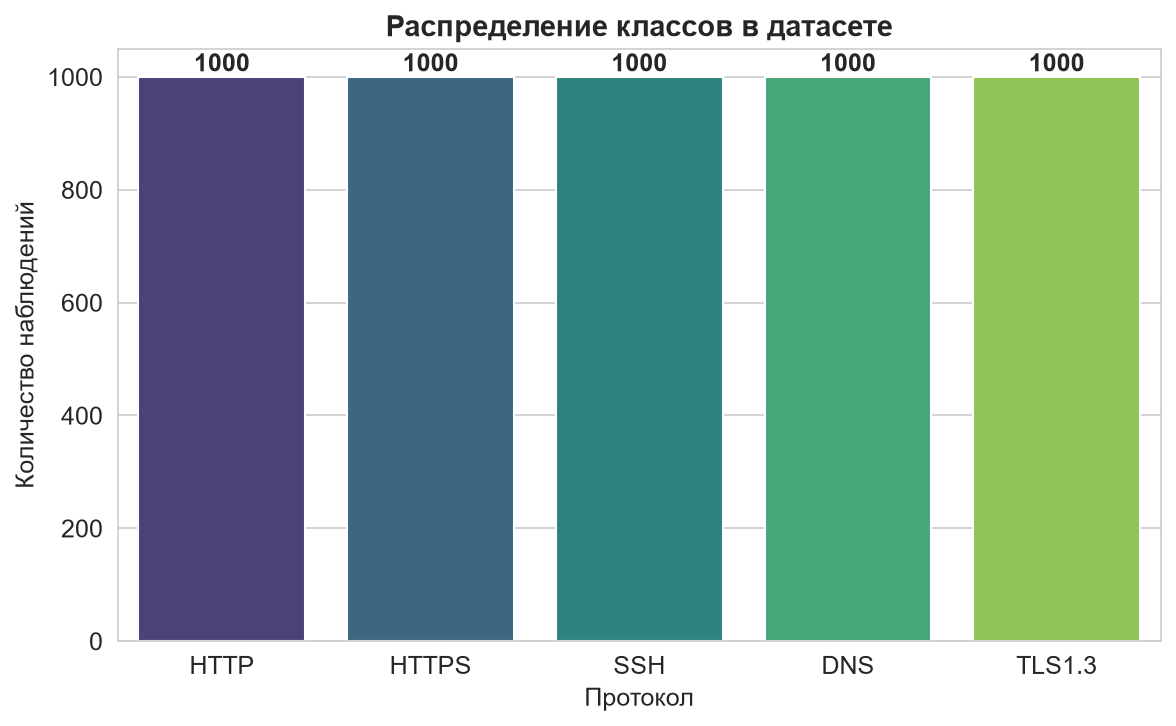

✓ Сохранено: ..\docs\assets\manual\class_distribution.png


In [2]:
# Распределение классов
fig, ax = plt.subplots(figsize=(8, 5))
class_counts = df['protocol'].value_counts()
sns.barplot(x=class_counts.index, y=class_counts.values, ax=ax, palette='viridis')
ax.set_title('Распределение классов в датасете', fontsize=14, fontweight='bold')
ax.set_xlabel('Протокол')
ax.set_ylabel('Количество наблюдений')
for i, v in enumerate(class_counts.values):
    ax.text(i, v + 10, str(v), ha='center', fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'class_distribution.png', bbox_inches='tight')
plt.show()
print(f"✓ Сохранено: {OUTPUT_DIR / 'class_distribution.png'}")

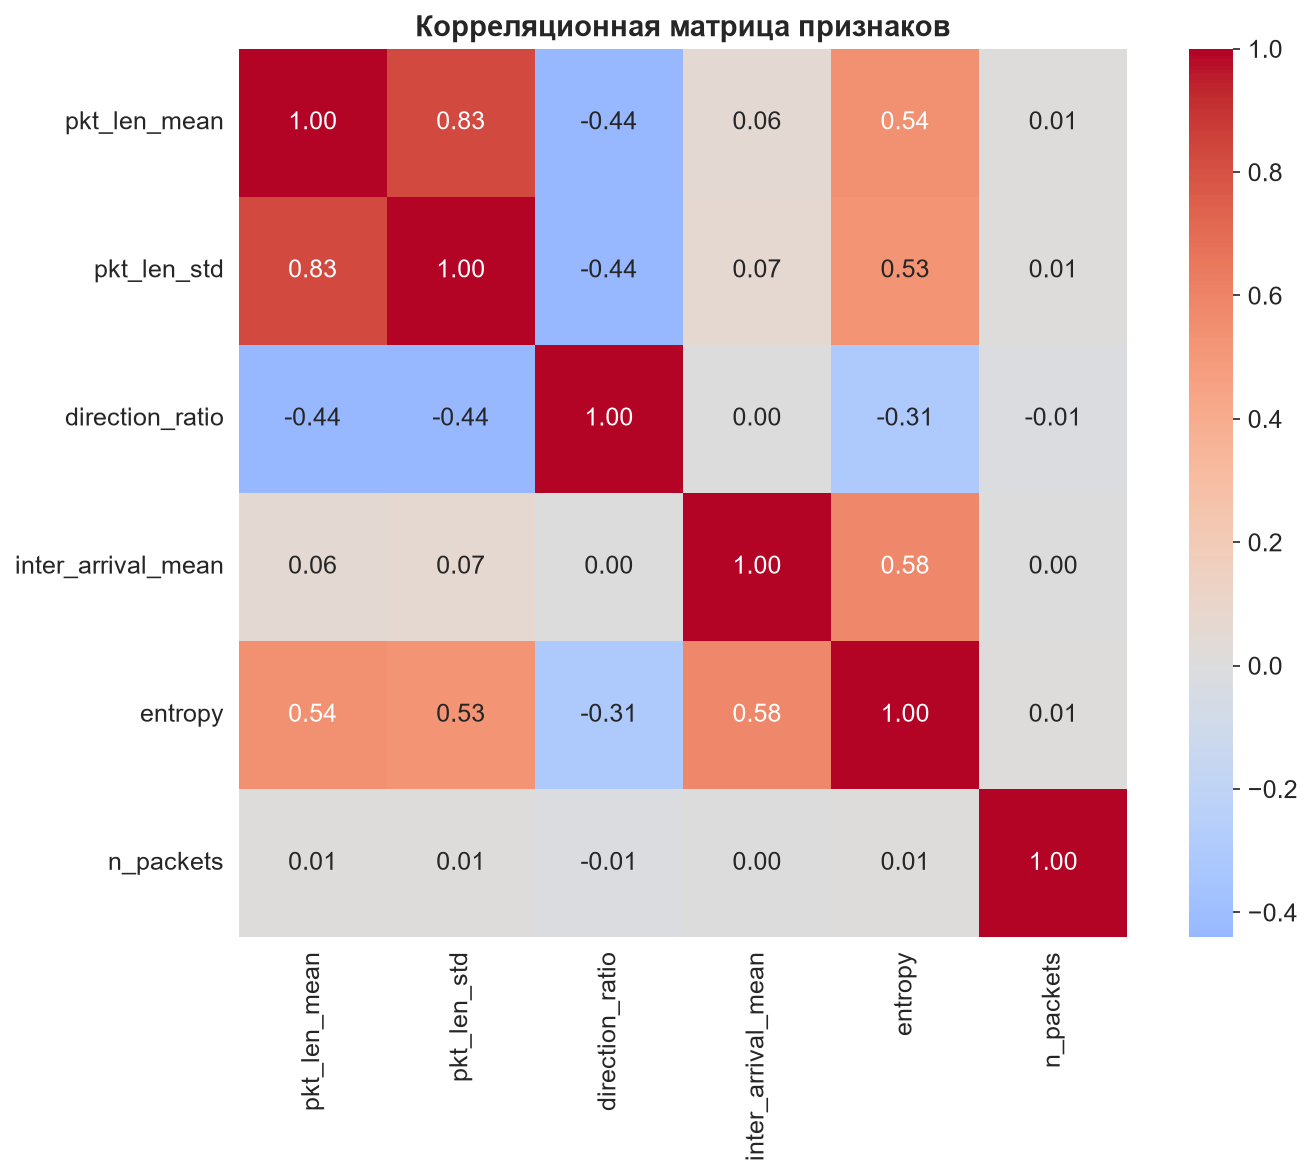

✓ Сохранено: ..\docs\assets\manual\correlation_matrix.png


In [3]:
# Корреляционная матрица признаков
feature_cols = ['pkt_len_mean', 'pkt_len_std', 'direction_ratio', 
                'inter_arrival_mean', 'entropy', 'n_packets']

fig, ax = plt.subplots(figsize=(10, 8))
corr_matrix = df[feature_cols].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, 
            fmt='.2f', ax=ax, square=True)
ax.set_title('Корреляционная матрица признаков', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'correlation_matrix.png', bbox_inches='tight')
plt.show()
print(f"✓ Сохранено: {OUTPUT_DIR / 'correlation_matrix.png'}")

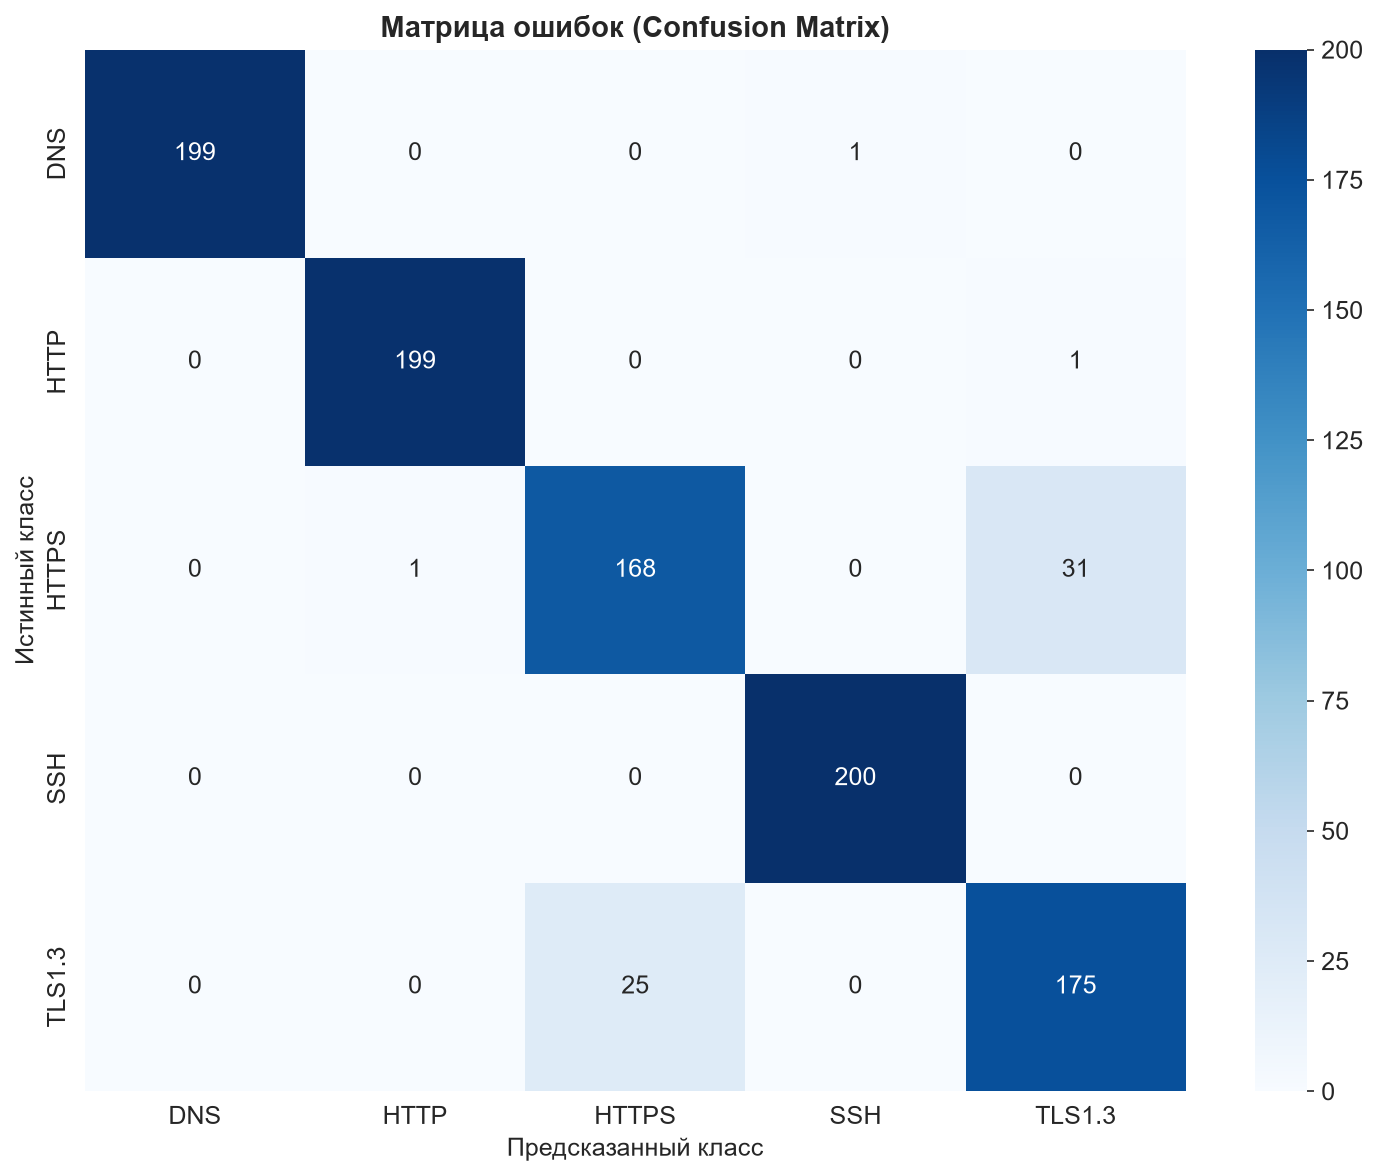

✓ Сохранено: ..\docs\assets\manual\confusion_matrix.png

Отчёт о классификации:
              precision    recall  f1-score   support

         DNS       1.00      0.99      1.00       200
        HTTP       0.99      0.99      0.99       200
       HTTPS       0.87      0.84      0.85       200
         SSH       1.00      1.00      1.00       200
      TLS1.3       0.85      0.88      0.86       200

    accuracy                           0.94      1000
   macro avg       0.94      0.94      0.94      1000
weighted avg       0.94      0.94      0.94      1000



In [4]:
# Обучение модели и матрица ошибок
X = df[feature_cols]
y = df['protocol']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

clf = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred, labels=clf.classes_)
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=clf.classes_, yticklabels=clf.classes_, ax=ax)
ax.set_xlabel('Предсказанный класс', fontsize=12)
ax.set_ylabel('Истинный класс', fontsize=12)
ax.set_title('Матрица ошибок (Confusion Matrix)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'confusion_matrix.png', bbox_inches='tight')
plt.show()
print(f"✓ Сохранено: {OUTPUT_DIR / 'confusion_matrix.png'}")

# Отчёт о классификации
report = classification_report(y_test, y_pred, output_dict=True)
print("\nОтчёт о классификации:")
print(classification_report(y_test, y_pred))

C:\Users\Admin\AppData\Local\Temp\ipykernel_11432\2373431323.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances, y=feature_cols, ax=ax, palette='viridis')


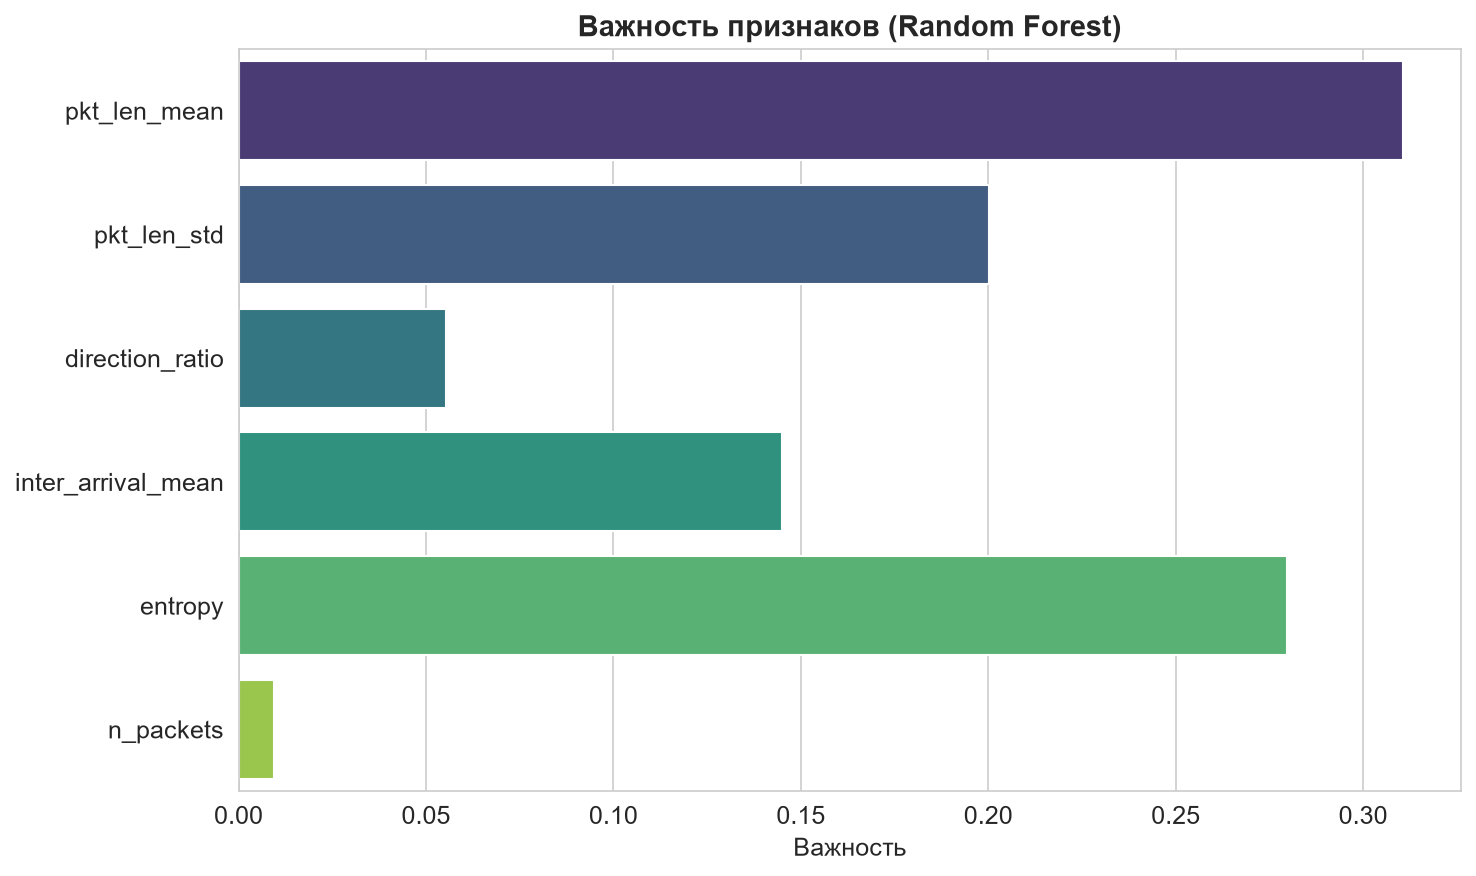

✓ Сохранено: ..\docs\assets\manual\feature_importance.png

ИТОГОВАЯ ТОЧНОСТЬ: 0.9410


In [5]:
# Важность признаков
importances = clf.feature_importances_
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=importances, y=feature_cols, ax=ax, palette='viridis')
ax.set_title('Важность признаков (Random Forest)', fontsize=14, fontweight='bold')
ax.set_xlabel('Важность', fontsize=12)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'feature_importance.png', bbox_inches='tight')
plt.show()
print(f"✓ Сохранено: {OUTPUT_DIR / 'feature_importance.png'}")

# Accuracy
accuracy = report['accuracy']
print(f"\n{'='*60}")
print(f"ИТОГОВАЯ ТОЧНОСТЬ: {accuracy:.4f}")
print(f"{'='*60}")